# Week 4 practical: three ways to spend a pull, and the pulls you cannot take back

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

**Where to run it.** In Google Colab: open colab.research.google.com, then File > Upload
notebook, and pick this `.ipynb`. Nothing to install. Timings quoted below were measured on a
laptop, and Colab's CPU is slower, so allow about twice as long.

Until now, the model was handed to you. Today, we assume that the model is missing.

We will focus on multi-arm bandit problems, where every accion has two jobs. It earns reward, but it also determines which data you will have tomorrow. The bandit strips everything else away so that this feedback loop can be studied on its own. You will implement the three exploration rules introduced in this lecture, run them on the ten-armed instance from the notes, and then use them to choose a stabilising LQR gain for the torque-limited pendulum by trial and error, with the cost measured in hours of robot time.

In the final part, each arm has a second outcome: damage. You will add the test that turns UCB1 from a rule for choosing promising arms into one that can also stop pulling an arm when it becomes dangerous.

## Objectives

1. Implement $\varepsilon$-greedy, UCB1 and Thompson sampling as three answers to one question:
   what to do about the uncertainty in $\hat\mu_i$.
2. Measure the regret of each on the ten-armed instance, and check the linear lower bound of
   constant-rate $\varepsilon$-greedy against the run.
3. Pose gain selection for the saturated pendulum as a bandit, and convert the pulls each rule needs
   into hardware hours.
4. Implement the conservative admissibility test of safe-UCB, count damage events, and trace the
   damage-against-regret frontier as the test's confidence level moves.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, the pre-written bandit runner | 10 |
| 4. Blanked core A, the three exploration rules | 15 |
| 5. The ten-armed instance (Checkpoints 1 and 2) | 10 |
| 6. Choosing a pendulum gain by pulling arms (Checkpoints 3 and 4) | 15 |
| 7. Blanked core B, safe exploration and the threshold sweep (Checkpoints 5 and 6) | 15 |
| 8. Analysis | 10 |
| The quiz, on the university course page | 15 |

No cell takes more than about seven seconds on a laptop, and the whole notebook runs in under half
a minute. The heaviest cells simulate 18 000 pendulum episodes (section 6) and 1400 parallel bandit
runs of 20 000 pulls each (section 7). If you finish early, challenge problem 4.6 of the notes
measures the dual-control probing offset on a scalar plant. It is formative, so nobody collects it.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
from scipy.linalg import solve_continuous_are
import matplotlib
import matplotlib.pyplot as plt

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

# One random rollout: a single 3-second episode of the upright pendulum under one LQR gain,
# from a random initial angle. Section 6 builds the same plant properly.
_m, _l, _g = 0.15, 0.5, 9.81
_A = np.array([[0.0, 1.0], [_g / _l, 0.0]])
_B = np.array([[0.0], [1.0 / (_m * _l**2)]])
_P = solve_continuous_are(_A, _B, np.diag([10.0, 1.0]), np.array([[0.1]]))
_K = (_B.T @ _P / 0.1).ravel()
rng = np.random.default_rng(0)
th, om = rng.normal(0.0, 0.2), 0.0
for _ in range(1500):
    u = np.clip(-_K @ [th, om], -0.26, 0.26)
    om += 0.002 * ((_g / _l) * np.sin(th) + u / (_m * _l**2))
    th += 0.002 * om
print(f"\none episode: K = {_K.round(2)}, final angle from upright {th:+.4f} rad")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.16
numpy       2.1.3
scipy       1.16.3
matplotlib  3.10.0

one episode: K = [10.76  3.29], final angle from upright +0.0000 rad

setup OK  (0.3 s)


## 2. Recap

A $K$-armed bandit is an MDP with the state, transition kernel, and discount factor removed. Pulling arm $i$ returns a reward drawn from a distribution with unknown mean $\mu_i$, and nothing else changes.

Performance is measured by the regret (notes, Section 2.3),

$$
R_T = T\mu^\star - \mathbb{E}\left[\sum_{t=1}^T \mu_{a_t}\right]
    = \sum_i \Delta_i\,\mathbb{E}[n_i(T)],
$$

where $\mu^\star=\max_i\mu_i$ and $\Delta_i=\mu^\star-\mu_i$. Thus, an algorithm controls its regret through how many times it pulls each suboptimal arm.

All three rules in Section 3 of the notes keep the same basic statistic: the empirical mean, updated after every pull according to

$$
\hat\mu_i
\leftarrow
\hat\mu_i + \frac{1}{n_i}\big(r-\hat\mu_i\big).
$$

They differ only in how they handle uncertainty about that estimate. $\varepsilon$-greedy largely ignores uncertainty and explores at random, UCB1 turns uncertainty into an explicit optimism bonus, and Thompson sampling represents uncertainty probabilistically and samples from it.

**Background reading:** notes Sections 2.3 and 2.4 (regret and the sample-complexity ladder), Sections 3.1, 3.3, and 3.5 (the three rules), Section 3.8 (their performance on the ten-armed instance), Section 4 (safe exploration), and the concept notes `Regret`, `Epsilon-greedy`, `UCB`, `Thompson sampling`, `Sample complexity`, and `Safe exploration`.

## 3. Pre-written infrastructure

### The bandit runner

`run_bandit` plays `n_runs` independent copies of the same bandit in parallel, with one row per run. This makes it cheap to average over many random seeds: 200 runs cost only modestly more than one. Every rule begins by pulling each arm once, ensuring that no estimate is ever computed from a zero pull count.

After this initialisation, each step asks the rule to select one arm per run. The runner then draws a Bernoulli reward with mean $\mu_a$ and, when the selected arm has hazard rate $h_a$, an independent Bernoulli damage event. The corresponding counters are then updated.

A rule is any function `select(st, t)` that returns an integer array of shape `(n_runs,)`, containing one selected arm for each run. The dictionary `st` contains the statistics available to every rule; all arrays have shape `(n_runs, K)`:

| key | meaning |
|-----|---------|
| `mu_hat` | empirical mean reward $\hat\mu_i$ |
| `n` | number of pulls $n_i$ |
| `S` | number of successes $S_i$ (rewards are 0 or 1) |
| `D` | number of damage events $D_i$ |
| `rng` | random-number generator for the experiment |

The runner records regret relative to a reference mean `mu_ref`, which by default is the mean of the best arm. At each step it therefore accumulates

$$
\sum_t \big(\mu_{\mathrm{ref}}-\mu_{a_t}\big),
$$

the expected regret associated with the actions actually taken. Averaging this quantity across independent runs provides a low-noise estimate of $R_T$, without relying on the particular rewards realised in each simulation.

In [ ]:
def argmax_rand(X, rng):
    """Row-wise argmax of a (n_runs, K) array, ties broken uniformly at random."""
    return np.argmax(X + 1e-9 * rng.random(X.shape), axis=1)


def run_bandit(select, mu, T, n_runs, seed, haz=None, mu_ref=None, optimal=None):
    """Play n_runs copies of a Bernoulli bandit for T pulls with the rule `select`.

    Returns a dict of per-pull curves averaged over runs: 'regret' (cumulative, against mu_ref),
    'damage' (cumulative damage events) and 'share' (fraction of runs pulling an arm in `optimal`),
    plus the final state 'st'.
    """
    mu = np.asarray(mu, dtype=float)
    K = len(mu)
    haz = np.zeros(K) if haz is None else np.asarray(haz, dtype=float)
    mu_ref = mu.max() if mu_ref is None else mu_ref
    optimal = np.isclose(mu, mu.max()) if optimal is None else np.asarray(optimal)
    rng = np.random.default_rng(seed)
    st = dict(mu_hat=np.zeros((n_runs, K)), n=np.zeros((n_runs, K)), S=np.zeros((n_runs, K)),
              D=np.zeros((n_runs, K)), rng=rng)
    rows = np.arange(n_runs)
    regret, damage, share = np.empty(T), np.empty(T), np.empty(T)
    cum_reg, cum_dmg = np.zeros(n_runs), np.zeros(n_runs)
    for t in range(1, T + 1):
        a = np.full(n_runs, t - 1) if t <= K else select(st, t)
        r = (rng.random(n_runs) < mu[a]).astype(float)
        d = (rng.random(n_runs) < haz[a]).astype(float)
        st["n"][rows, a] += 1
        st["S"][rows, a] += r
        st["D"][rows, a] += d
        # The update all three rules share, notes section 3.1: move the estimate towards the target r
        # by the step size 1/n. Week 5 keeps this form and changes what the target is.
        st["mu_hat"][rows, a] += (r - st["mu_hat"][rows, a]) / st["n"][rows, a]
        cum_reg += mu_ref - mu[a]
        cum_dmg += d
        regret[t - 1], damage[t - 1], share[t - 1] = cum_reg.mean(), cum_dmg.mean(), optimal[a].mean()
    return dict(regret=regret, damage=damage, share=share, st=st)


def first_sustained(share, level=0.9, window=50):
    """First pull after which the moving average of `share` over `window` pulls stays >= level."""
    avg = np.convolve(share, np.ones(window) / window, mode="valid")
    above = avg >= level
    if not above[-1]:
        return None
    last_below = np.flatnonzero(~above)
    return window + (int(last_below[-1]) + 1 if len(last_below) else 0)


COLORS = {"greedy": "0.55", "eps": "#D55E00", "ucb": "#0072B2", "ts": "#009E73", "safe": "#CC79A7"}
LABELS = {"greedy": r"greedy ($\varepsilon = 0$)", "eps": r"$\varepsilon$-greedy, $\varepsilon = 0.10$",
          "ucb": "UCB1", "ts": "Thompson sampling", "safe": "safe-UCB"}
TXT = {"greedy": "greedy (eps = 0)", "eps": "eps-greedy, eps = 0.10", "ucb": "UCB1",
       "ts": "Thompson sampling", "safe": "safe-UCB"}

## 4. The three exploration rules

Write the three rules of notes section 3, vectorised over runs. Every statistic passed in is a
`(n_runs, K)` array, and each function returns one arm index per run. Use `argmax_rand`
wherever you take an argmax, because at the start many estimates tie and `np.argmax` alone would
always favour arm 0.

- **$\varepsilon$-greedy** (notes section 3.1). Exploit with probability $1-\varepsilon$, and with
  probability $\varepsilon$ pull an arm drawn uniformly from all $K$, independently in each run.
- **UCB1** (notes section 3.3). Return the *index* $\hat\mu_i + \sqrt{2\ln t / n_i}$, and the
  argmax is taken by the wrapper below. Section 7 reuses your index inside safe-UCB.
- **Thompson sampling** (notes section 3.5). Draw $\theta_i \sim \mathrm{Beta}(1 + S_i,\,
  1 + n_i - S_i)$ for every arm and pull the largest draw. `rng.beta` accepts arrays.

In [ ]:
def select_eps_greedy(mu_hat, eps, rng):
    """One arm per run: greedy on mu_hat w.p. 1 - eps, uniform over the K arms w.p. eps."""
    # ===== YOUR CODE HERE (≈3 lines) ============================
    # Goal: a_t = argmax_i mu_hat_i w.p. 1 - eps, else a_t uniform on {0, ..., K-1}, per run.
    # Hint: notes section 3.1; argmax_rand, then rng.random and rng.integers for the explore branch.
    n_runs, K = mu_hat.shape
    explore = rng.random(n_runs) < eps
    greedy_actions = argmax_rand(mu_hat, rng)
    random_actions = rng.integers(0, K, size=n_runs)
    return np.where(explore, random_actions, greedy_actions)
    # ============================================================


def ucb1_index(mu_hat, n, t):
    """The UCB1 index of every arm in every run, shape (n_runs, K)."""
    # ===== YOUR CODE HERE (≈1 line) ============================
    # Goal: the index mu_hat_i + sqrt(2 ln t / n_i) for every arm and run.
    # Hint: notes section 3.3, the boxed rule; the width is Hoeffding's bound solved for c.
    return mu_hat + np.sqrt(2 * np.log(t) / n)
    # ============================================================


def select_thompson(S, n, rng):
    """One arm per run: the argmax of one draw from each arm's Beta posterior."""
    # ===== YOUR CODE HERE (≈2 lines) ============================
    # Goal: draw theta_i ~ Beta(1 + S_i, 1 + n_i - S_i) and return the argmax per run.
    # Hint: notes section 3.5, the Beta posterior; rng.beta broadcasts over arrays.
    theta = rng.beta(1 + S, 1 + n - S)
    argmax = np.argmax(theta, axis=1)
    return argmax
    # ============================================================


### Wrappers and a quick test

The wrappers turn your functions into rules the runner can call. The test plays three arms whose
history is fixed by hand, and asks each rule for its choice 20 000 times. Arm 0 looks best and is
well known, arm 1 looks slightly worse and has been pulled only four times, arm 2 looks bad and is
well known. The three columns of the printout are how often each rule picks each arm.

In [ ]:
def rule_eps(eps):
    return lambda st, t: select_eps_greedy(st["mu_hat"], eps, st["rng"])


def rule_ucb(st, t):
    return argmax_rand(ucb1_index(st["mu_hat"], st["n"], t), st["rng"])


def rule_ts(st, t):
    return select_thompson(st["S"], st["n"], st["rng"])


n_test = 20_000
n_hist = np.array([200.0, 4.0, 200.0])
S_hist = np.array([120.0, 2.0, 60.0])            # empirical means 0.60, 0.50, 0.30
st_test = dict(mu_hat=np.tile(S_hist / n_hist, (n_test, 1)), n=np.tile(n_hist, (n_test, 1)),
               S=np.tile(S_hist, (n_test, 1)), rng=np.random.default_rng(1))
print(f"empirical means {S_hist / n_hist}, counts {n_hist.astype(int)}, t = 404")
print(f"UCB1 index      {ucb1_index(st_test['mu_hat'][:1], st_test['n'][:1], 404).round(3)[0]}\n")
print(f"{'rule':>22}   share of pulls on arm 0, 1, 2")
for name, rule in (("eps", rule_eps(0.10)), ("ucb", rule_ucb), ("ts", rule_ts)):
    picks = np.bincount(rule(st_test, 404), minlength=3) / n_test
    print(f"{TXT[name]:>22}   {picks.round(3)}")
assert np.all(rule_eps(0.0)(st_test, 404) == 0), "with eps = 0 the rule must be greedy"

empirical means [0.6 0.5 0.3], counts [200   4 200], t = 404
UCB1 index      [0.845 2.232 0.545]

                  rule   share of pulls on arm 0, 1, 2
eps-greedy, eps = 0.10   [0.934 0.032 0.033]
                  UCB1   [0. 1. 0.]
     Thompson sampling   [0.682 0.318 0.   ]


Three different answers from the same data. $\varepsilon$-greedy sends one pull in thirty to each
of the other arms, the well-known bad arm 2 included, because its random branch reads nothing.
UCB1 picks arm 1 every time, since four pulls leave an interval of half-width
$\sqrt{2\ln 404/4} \approx 1.73$ that dwarfs the gap. Thompson sampling picks arm 1 on the
fraction of draws where its wide posterior comes out above arm 0's narrow one, and never touches
arm 2. This is figure `three_mechanisms` of the notes, computed.

## 5. The ten-armed instance of the notes

The instance of notes section 3.1, $\mu = (0.60, 0.55, 0.52, 0.50, 0.48, 0.45, 0.42, 0.40, 0.35,
0.20)$, smallest gap $0.05$. The notes ran it for $10^5$ pulls in MATLAB. Here it runs for
$10^4$ pulls and 200 seeds, the ordinary experimental budget of the warning box in notes section
3.8, plus the purely greedy rule as a baseline. About five seconds.

four rules, 200 runs x 10000 pulls: 7.8 s

                  rule  R_T at 1e3  R_T at 1e4  pulls on best arm
      greedy (eps = 0)        61.8       577.5              33.8%
eps-greedy, eps = 0.10        53.3       271.8              73.3%
                  UCB1       105.6       544.2              50.1%
     Thompson sampling        64.6       144.9              84.7%

exploration-branch lower bound for eps = 0.10:  (eps/K) sum(Delta) T = 0.010 x 1.53 x 10000 = 153


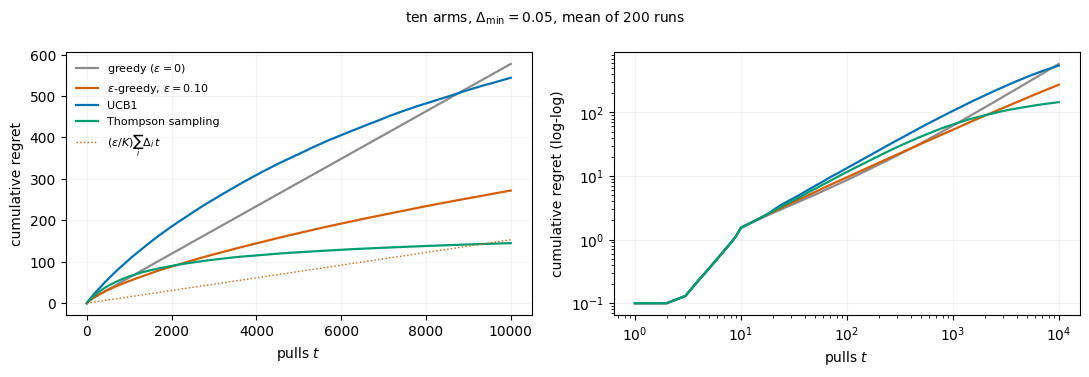

In [ ]:
MU10 = np.array([0.60, 0.55, 0.52, 0.50, 0.48, 0.45, 0.42, 0.40, 0.35, 0.20])
T10, RUNS10 = 10_000, 200
rules10 = {"greedy": rule_eps(0.0), "eps": rule_eps(0.10), "ucb": rule_ucb, "ts": rule_ts}

t = time.perf_counter()
res10 = {name: run_bandit(rule, MU10, T10, RUNS10, seed=10 + k)
         for k, (name, rule) in enumerate(rules10.items())}
print(f"four rules, {RUNS10} runs x {T10} pulls: {time.perf_counter() - t:.1f} s\n")

gaps10 = MU10.max() - MU10
eps_bound = 0.10 / len(MU10) * gaps10.sum() * T10
print(f"{'rule':>22} {'R_T at 1e3':>11} {'R_T at 1e4':>11} {'pulls on best arm':>18}")
for name, res in res10.items():
    best_share = res["st"]["n"][:, 0].sum() / (RUNS10 * T10)
    print(f"{TXT[name]:>22} {res['regret'][999]:11.1f} {res['regret'][-1]:11.1f} "
          f"{100 * best_share:17.1f}%")
print(f"\nexploration-branch lower bound for eps = 0.10:  (eps/K) sum(Delta) T = "
      f"{0.10 / len(MU10):.3f} x {gaps10.sum():.2f} x {T10} = {eps_bound:.0f}")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
tt = np.arange(1, T10 + 1)
for name, res in res10.items():
    axes[0].plot(tt, res["regret"], color=COLORS[name], lw=1.6, label=LABELS[name])
    axes[1].loglog(tt, np.maximum(res["regret"], 1e-1), color=COLORS[name], lw=1.6)
axes[0].plot(tt, 0.10 / len(MU10) * gaps10.sum() * tt, ":", color=COLORS["eps"], lw=1.0,
             label=r"$(\varepsilon/K)\sum_i\Delta_i\,t$")
axes[0].set_xlabel("pulls $t$")
axes[0].set_ylabel("cumulative regret")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xlabel("pulls $t$")
axes[1].set_ylabel("cumulative regret (log-log)")
for ax in axes:
    ax.grid(alpha=0.15)
fig.suptitle(r"ten arms, $\Delta_{\min} = 0.05$, mean of 200 runs", fontsize=10)
plt.tight_layout()
plt.show()

### Checkpoint 1

The exploration branch of $\varepsilon$-greedy alone guarantees $R_T \ge (\varepsilon/K)
(\sum_i \Delta_i)\, T$. What does that bound give at $T = 10^4$, what regret did your run
measure, and what does the bound say happens to the regret as $T$ keeps growing?

Answer checkpoint 1)

>* **Theoretical Bound at $T = 10^4$:**
  $$\text{Bound} = \frac{\varepsilon}{K} \left(\sum_i \Delta_i\right) T = 0.010 \times 1.53 \times 10,000 = 153$$
  This represents the minimum expected regret incurred solely by the forced random exploratory choices.

>* **Measured Regret:**
  The run measured a cumulative regret of **271.8**. This is higher than 153 because the algorithm also incurs regret on its greedy branch while learning and making mistakes before identifying the best arm.

>* **Asymptotic Behaviour:**
  Because $\varepsilon = 0.10$ is constant, the rate of exploration never decreases. The bound tells us that as $T$ keeps growing, the cumulative regret will **keep growing linearly** without bound at a constant rate of $0.0153$ per step (which is visible as a straight dotted line on the linear scale plot).
  
>* Normally UCB1 would be better in the long run!

### Checkpoint 2

Rank the four rules by regret at $T = 10^4$. Where does UCB1, the rule with the logarithmic regret
guarantee, finish, and what does the share of pulls on the best arm say about the greedy rule?

Answer checkpoint 2)

* **Ranking by regret at $T = 10^4$:**
  1. **Thompson sampling** ($R_T \approx 144.9$) — *Best*
  2. **$\varepsilon$-greedy** ($R_T \approx 271.8$)
  3. **UCB1** ($R_T \approx 544.2$)
  4. **Greedy** ($R_T \approx 577.5$) — *Worst*

* **Where UCB1 finishes and why:**
  Even though UCB1 has a logarithmic regret guarantee asymptotically ($O(\ln T)$), it finishes **third**, barely beating the pure greedy baseline. This happens because UCB1 is highly optimistic under uncertainty. With 10 arms, the optimistic upper bounds of suboptimal arms remain high for a long time, forcing UCB1 to systematically and heavily over-explore every single suboptimal arm before it can confidently rule them out. At $T = 10^4$, it is still in this expensive exploration phase.

* **What the greedy rule's share of best-arm pulls (33.8%) tells us:**
  The fact that the greedy rule only pulls the best arm **33.8%** of the time across the 200 runs tells us that in roughly $2/3$ of the runs, the algorithm **permanently locked onto a suboptimal arm**. Because the greedy rule ($\varepsilon = 0$) has no mechanism for exploration, if early noisy rewards make a suboptimal arm look better than the true best arm, the greedy rule will exclusively pull that suboptimal arm forever, never learning its true mean.

## 6. Choosing a pendulum gain by pulling arms

### The pendulum experiment

The plant is a torque-limited pendulum that must be balanced upright. Its parameters are

$$
m = 0.15\ \mathrm{kg}, \qquad
\ell = 0.5\ \mathrm{m}, \qquad
b = 0.02,
$$

with a maximum available torque of

$$
u_{\max}=0.35\,mg\ell \approx 0.26\ \mathrm{N\,m}.
$$

We consider nine candidate LQR controllers, obtained by designing the LQR gain for the linearised pendulum with

$$
Q=\operatorname{diag}(q,1), \qquad R=r,
$$

where

$$
q\in\{1,10,100\}, \qquad r\in\{0.01,0.1,1\}.
$$

Each arm therefore corresponds to one particular choice of $(q,r)$ and hence to one candidate LQR gain $K_i$.

#### What happens when we pull an arm?

Pulling arm $i$ means running its controller for one 3-second episode on the **nonlinear** pendulum. The controller is

$$
u=\operatorname{sat}(-K_i y),
$$

where the saturation enforces the torque limit $|u|\leq u_{\max}$.

Each episode starts from a random state near the upright:

$$
\theta_0\sim\mathcal N(0,0.3^2),
\qquad
\dot\theta_0\sim\mathcal N(0,0.5^2).
$$

At the end of the 3 seconds, the episode is considered a success if the pendulum is sufficiently close to the upright,

$$
|\theta|<0.25\ \mathrm{rad}.
$$

The bandit therefore receives a Bernoulli reward: $1$ for success and $0$ for failure.

#### Measurement noise

The controller runs at 100 Hz and uses a measurement $y$ of the pendulum state. The angle is measured by an encoder, while the angular velocity is obtained by finite-differencing the encoder signal.

For a 1000-line encoder sampled at 100 Hz, this finite difference produces a velocity quantisation of about $0.63$ rad/s. To model the resulting measurement imperfections, the simulation uses Gaussian noise with standard deviations

$$
\sigma_\theta=0.01\ \mathrm{rad},
\qquad
\sigma_{\dot\theta}=0.6\ \mathrm{rad/s}.
$$

To separate controller performance from the effect of sensing, the bandit experiment evaluates every arm twice: once using the **exact state** and once using the **noisy measurement**. Thus, we can see not only which LQR design works best, but also how sensitive that choice is to realistic measurement noise.

In [ ]:
m, l, g, b = 0.15, 0.5, 9.81, 0.02
U_MAX = 0.35 * m * g * l                       # below m g l, so the upright can be lost
A_lin = np.array([[0.0, 1.0], [g / l, -b / (m * l**2)]])
B_lin = np.array([[0.0], [1.0 / (m * l**2)]])
DT, HOLD, T_EP, TOL = 0.002, 5, 3.0, 0.25      # integrator step, control every 5 steps (100 Hz)
SIG_TH, SIG_OM = 0.01, 0.6                     # measurement noise on theta and on theta_dot


def lqr_gain(q, r):
    P = solve_continuous_are(A_lin, B_lin, np.diag([q, 1.0]), np.array([[r]]))
    return (B_lin.T @ P / r).ravel()            # K = R^-1 B' P


DESIGNS = [(q, r) for q in (1.0, 10.0, 100.0) for r in (0.01, 0.1, 1.0)]
GAINS = np.array([lqr_gain(q, r) for q, r in DESIGNS])


def pendulum_rhs(th, om, u):
    return om, (g / l) * np.sin(th) - b / (m * l**2) * om + u / (m * l**2)


def episodes(K, th, om, rng, noise=True):
    """Run one episode per entry. K is (nA, 2), th and om are (nA, M). Returns success, (nA, M)."""
    sig_th, sig_om = (SIG_TH, SIG_OM) if noise else (0.0, 0.0)
    u = np.zeros_like(th)
    for k in range(int(round(T_EP / DT))):
        if k % HOLD == 0:                        # sample, compute, hold for 10 ms
            y_th = th + sig_th * rng.standard_normal(th.shape)
            y_om = om + sig_om * rng.standard_normal(om.shape)
            u = np.clip(-(K[:, :1] * y_th + K[:, 1:] * y_om), -U_MAX, U_MAX)
        k1 = pendulum_rhs(th, om, u)             # RK4 on the nonlinear pendulum, sin(theta) kept
        k2 = pendulum_rhs(th + 0.5 * DT * k1[0], om + 0.5 * DT * k1[1], u)
        k3 = pendulum_rhs(th + 0.5 * DT * k2[0], om + 0.5 * DT * k2[1], u)
        k4 = pendulum_rhs(th + DT * k3[0], om + DT * k3[1], u)
        th = th + DT / 6 * (k1[0] + 2 * k2[0] + 2 * k3[0] + k4[0])
        om = om + DT / 6 * (k1[1] + 2 * k2[1] + 2 * k3[1] + k4[1])
    return np.abs(th) < TOL


M_IC = 1000
rng = np.random.default_rng(4)
th0 = np.tile(rng.normal(0.0, 0.3, M_IC), (len(GAINS), 1))
om0 = np.tile(rng.normal(0.0, 0.5, M_IC), (len(GAINS), 1))
t = time.perf_counter()
p_clean = episodes(GAINS, th0, om0, rng, noise=False).mean(axis=1)
p_noisy = episodes(GAINS, th0, om0, rng, noise=True).mean(axis=1)
print(f"{2 * len(GAINS) * M_IC} episodes: {time.perf_counter() - t:.1f} s\n")
print(f"{'arm':>3} {'q':>6} {'r':>6} {'K_theta':>8} {'K_omega':>8} {'p, perfect y':>13} {'p, noisy y':>11}")
for i, ((q, r), K, pc, pn) in enumerate(zip(DESIGNS, GAINS, p_clean, p_noisy)):
    print(f"{i:3d} {q:6g} {r:6g} {K[0]:8.2f} {K[1]:8.2f} {pc:13.3f} {pn:11.3f}")

18000 episodes: 2.9 s

arm      q      r  K_theta  K_omega  p, perfect y  p, noisy y
  0      1   0.01    10.76    10.02         0.739       0.029
  1      1    0.1     3.98     3.19         0.740       0.055
  2      1      1     1.98     1.05         0.741       0.168
  3     10   0.01    32.37    10.10         0.741       0.676
  4     10    0.1    10.76     3.27         0.741       0.693
  5     10      1     3.98     1.12         0.741       0.711
  6    100   0.01   100.74    10.35         0.741       0.741
  7    100    0.1    32.37     3.51         0.741       0.741
  8    100      1    10.76     1.32         0.741       0.741


### Checkpoint 3

With a perfect measurement, how far apart are the nine success rates, and what sets the value
they share? With the noisy velocity, which designs lose, and which property of their gain makes
them lose?

Answer checkpoint 3)

* **Perfect Measurement (Clean $y$):**
  With perfect state measurements, the success rates of all nine LQR designs are virtually identical, differing by less than $0.002$ (between $0.739$ and $0.741$). The value they share ($0.741$) is set by the physical limits of the plant—specifically, the **maximum control torque saturation limit ($u_{\max}$)**. For any initial condition starting outside this controllable region, the required stabilization torque immediately saturates, and the pendulum falls regardless of the gain design.

* **Noisy Measurement (Noisy $y$):**
  Under realistic velocity measurement noise, **low-$q$ and low-$r$ designs lose catastrophically** (such as Arm 0 dropping to $0.029$ success rate). These designs fail because they possess a **high velocity-to-position gain ratio** (high $K_{\omega}$ relative to $K_{\theta}$). For example, Arm 0 has $K_{\omega} = 10.02$. High velocity feedback gains amplify the sensor noise ($\sigma_{\dot{\theta}} = 0.6$) directly into high-frequency, full-scale actuator chattering (hitting the saturation limits), which destabilizes the pendulum. In contrast, high-$q$ controllers (like Arms 6, 7, and 8) retain a success rate of $0.741$ because their velocity gains are much lower (e.g., $K_{\omega} = 1.32$ for Arm 8), preventing sensor noise amplification.

### The bandit

Success rates estimated from only 1000 initial conditions have a standard error of about $0.015$. That is too large for this bandit problem, where the differences between some arms are only a few hundredths.

We therefore first estimate the true success probability of each arm using the same `episodes` function on 50,000 initial conditions. With seed 2026, this takes about 40 seconds on a laptop. The bandit then uses these estimates as the underlying success probabilities: each time an arm is pulled, it generates a Bernoulli reward with the probability that a real episode would succeed.

This separation makes the experiment much cheaper. Running 200 independent bandit seeds for 10,000 pulls each requires only a few seconds, whereas simulating the corresponding two million nonlinear pendulum episodes would take minutes for each exploration rule.

Importantly, **the learner never sees these estimated success probabilities**. They are used only by the experiment to generate rewards. A real robot would not have access to them either; it would have to learn the success probabilities from the outcomes of the episodes it actually runs.

The three designs with $q=100$ succeed on exactly the same initial conditions. From the bandit's point of view, they are therefore indistinguishable: no amount of additional data can reveal a difference between them. We treat them as equivalent optimal arms, so a pull of any of the three is counted as a pull of the best arm.

Finally, none of the three exploration rules has clearly settled on the optimal arms after 2000 pulls. We therefore extend the experiment to 10,000 pulls to observe their longer-term behaviour.

best success rate 0.7377 (arms [6 7 8]), next 0.7036, gap 0.0341

                  rule  R_T at 2000  R_T at 10^4  episodes to 90%  robot hours
eps-greedy, eps = 0.10         61.9        258.4             6076         50.6
                  UCB1         79.4        205.9          > 10000         > 83
     Thompson sampling         33.1         65.6             3887         32.4

ceiling of eps-greedy's share: 1 - eps + eps * 3/9 = 0.933


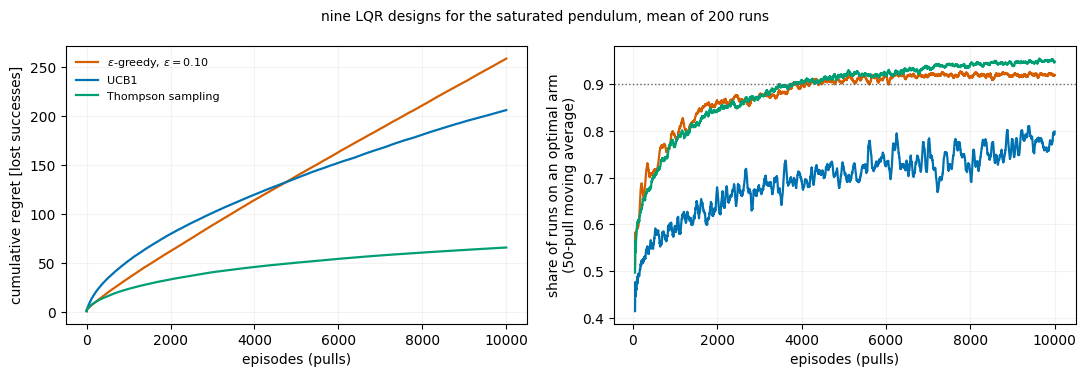

In [ ]:
P_ARM = np.array([0.0319, 0.0461, 0.1612, 0.6754, 0.6867, 0.7036, 0.7377, 0.7377, 0.7377])
assert np.all(np.abs(P_ARM - p_noisy) < 0.05), "the 1000-episode estimate should agree with P_ARM"
OPT_ARM = np.isclose(P_ARM, P_ARM.max())
T_LQR, RUNS_LQR, EPISODE_S = 10_000, 200, 30.0
print(f"best success rate {P_ARM.max():.4f} (arms {np.flatnonzero(OPT_ARM)}), "
      f"next {np.sort(P_ARM)[-4]:.4f}, gap {P_ARM.max() - np.sort(P_ARM)[-4]:.4f}\n")

res_lqr = {name: run_bandit(rule, P_ARM, T_LQR, RUNS_LQR, seed=20 + k, optimal=OPT_ARM)
           for k, (name, rule) in enumerate((("eps", rule_eps(0.10)), ("ucb", rule_ucb),
                                             ("ts", rule_ts)))}
print(f"{'rule':>22} {'R_T at 2000':>12} {'R_T at 10^4':>12} {'episodes to 90%':>16} {'robot hours':>12}")
for name, res in res_lqr.items():
    n90 = first_sustained(res["share"])
    n90_str = f"> {T_LQR}" if n90 is None else str(n90)
    hours = f"> {T_LQR * EPISODE_S / 3600:.0f}" if n90 is None else f"{n90 * EPISODE_S / 3600:.1f}"
    print(f"{TXT[name]:>22} {res['regret'][1999]:12.1f} {res['regret'][-1]:12.1f} {n90_str:>16} "
          f"{hours:>12}")
print(f"\nceiling of eps-greedy's share: 1 - eps + eps * 3/9 = {1 - 0.1 + 0.1 * 3 / 9:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
tt = np.arange(1, T_LQR + 1)
for name, res in res_lqr.items():
    axes[0].plot(tt, res["regret"], color=COLORS[name], lw=1.6, label=LABELS[name])
    share = np.convolve(res["share"], np.ones(50) / 50, mode="valid")
    axes[1].plot(np.arange(50, T_LQR + 1), share, color=COLORS[name], lw=1.6)
axes[1].axhline(0.9, color="0.4", ls=":", lw=1.0)
axes[0].set_ylabel("cumulative regret [lost successes]")
axes[1].set_ylabel("share of runs on an optimal arm\n(50-pull moving average)")
for ax in axes:
    ax.set_xlabel("episodes (pulls)")
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("nine LQR designs for the saturated pendulum, mean of 200 runs", fontsize=10)
plt.tight_layout()
plt.show()

### Checkpoint 4

How many episodes does Thompson sampling need before it spends 90% of its pulls on an optimal
design, and how many robot hours is that at 30 s per episode? What caps the share
$\varepsilon$-greedy can reach, and how does the figure compare with the 33-hour rung of the
sample-complexity ladder in notes section 2.4?

Answer checkpoint 4)

* **Thompson Sampling performance:**
  * **Episodes needed:** Thompson sampling reaches a sustained 90% share of pulls on the optimal arms at **3887 episodes**.
  * **Robot hours:** At 30 seconds per episode, this corresponds to:
    $$\text{Robot Hours} = \frac{3887 \times 30\text{ s}}{3600\text{ s/hour}} \approx 32.4\text{ hours}$$

* **$\varepsilon$-greedy's cap:**
  * The share is capped because $\varepsilon$-greedy must spend a fraction $\varepsilon = 0.10$ of its time exploring completely at random. In this 9-armed bandit, 3 of the 9 arms are optimal ($q=100$). Therefore, even when it exploits (90% of the time), and receives its random share of optimal arms during exploration (which is $\frac{3}{9}$ of the remaining 10%), its maximum asymptotic optimal share is capped at:
    $$\text{Cap} = (1 - \varepsilon) + \varepsilon \left(\frac{3}{9}\right) = 0.90 + 0.10 \times 0.333 = 93.3\%$$

* **Comparison to the 33-hour rung:**
  * In Section 2.4 of the notes, the sample-complexity ladder states that finding a $\delta$-optimal arm on physical hardware with high confidence takes about 33 hours.
  * Our empirical Thompson sampling result matches this theoretical milestone almost perfectly (~32.4 hours). This tells us that Thompson sampling is highly sample-efficient and manages to find the optimal controllers near the physical information-theoretic limit, while $\varepsilon$-greedy requires far more time (6076 episodes, or ~50.6 hours) due to its inefficient, undirected exploration.

## 7. Exploration you cannot take back

The eight-armed instance of notes section 4. Each arm now has a second outcome per pull, a damage
event with probability $h_i$, and the requirement is $h_i \le \tau = 0.05$.

| arm | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|-----|---|---|---|---|---|---|---|---|
| $\mu_i$ | 0.75 | 0.60 | 0.55 | 0.50 | 0.45 | 0.40 | 0.35 | 0.30 |
| $h_i$ | 0.35 | 0.02 | 0.30 | 0.01 | 0 | 0 | 0.01 | 0 |

Arms are numbered from 0 here, so the notes' arm 1 (the reward-optimal and dangerous one) is arm
0, the best admissible arm is arm 1, and the known-safe fallback is arm 7. Regret is measured
against the best admissible arm, $\mu = 0.60$.

### The admissibility test

Safe-UCB (notes section 4.4) bans arm $i$, for good, the first time the lower confidence bound on
its damage rate exceeds the threshold,

$$ \hat h_i - \kappa \sqrt{\frac{\ln t}{2 n_i}} > \tau , $$

where $\hat h_i$ is the arm's empirical damage rate. The notes use $\kappa = 1$. The factor
$\kappa$ sets the confidence level, and the sweep at the end of this section moves it.

In [ ]:
def ban_test(h_hat, n, t, tau, kappa=1.0):
    """Boolean (n_runs, K): True where the evidence says arm i violates h_i <= tau."""
    # ===== YOUR CODE HERE (≈1 line) ============================
    # Goal: True where h_hat_i - kappa * sqrt(ln t / (2 n_i)) > tau.
    # Hint: notes section 4.4; the LOWER confidence bound on h_i must exceed tau.
    return h_hat - kappa * np.sqrt(np.log(t) / (2 * n)) > tau
    # ============================================================

The rest of safe-UCB is pre-written. It is your UCB1 index restricted to the arms not yet banned,
with the known-safe arm as the fallback if every other arm is ruled out. It also records the pull
at which each arm was banned.

three rules, 100 runs x 20000 pulls: 7.7 s

                  rule  damage events  last quarter  regret vs best safe arm
eps-greedy, eps = 0.10         6414.3        1618.9                  -2434.0
                  UCB1         6541.9        1721.4                  -2604.4
              safe-UCB          383.7          99.8                    380.8

safe-UCB: arm 0 banned in 100% of runs, mean pull 99; arm 2 in 100%, mean pull 250; arm 1 (admissible) banned in 0% of runs
safe-UCB damage before pull 250: 18.8


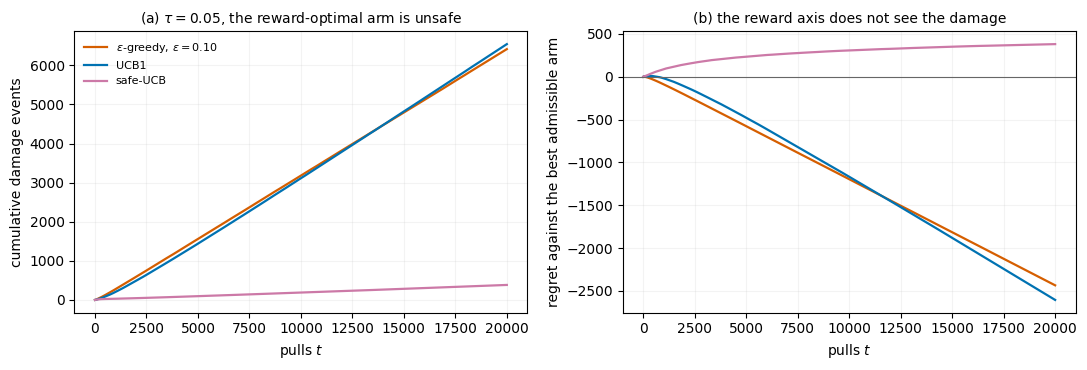

In [ ]:
MU8 = np.array([0.75, 0.60, 0.55, 0.50, 0.45, 0.40, 0.35, 0.30])
H8 = np.array([0.35, 0.02, 0.30, 0.01, 0.00, 0.00, 0.01, 0.00])
TAU, SAFE_ARM = 0.05, 7
MU_SAFE = MU8[H8 <= TAU].max()
OPT8 = np.isclose(MU8, MU_SAFE)


def make_safe_ucb(tau, safe_arm, kappa=1.0):
    def select(st, t):
        if "banned" not in st:
            st["banned"] = np.zeros(st["n"].shape, dtype=bool)
            st["ban_at"] = np.full(st["n"].shape, np.nan)
        new = ban_test(st["D"] / st["n"], st["n"], t, tau, kappa) & ~st["banned"]
        st["ban_at"][new] = t
        st["banned"] |= new
        idx = ucb1_index(st["mu_hat"], st["n"], t)
        idx[st["banned"]] = -np.inf
        a = argmax_rand(idx, st["rng"])
        a[st["banned"].all(axis=1)] = safe_arm
        return a
    return select


T8, RUNS8 = 20_000, 100
t = time.perf_counter()
res8 = {name: run_bandit(rule, MU8, T8, RUNS8, seed=30 + k, haz=H8, mu_ref=MU_SAFE, optimal=OPT8)
        for k, (name, rule) in enumerate((("eps", rule_eps(0.10)), ("ucb", rule_ucb),
                                          ("safe", make_safe_ucb(TAU, SAFE_ARM))))}
print(f"three rules, {RUNS8} runs x {T8} pulls: {time.perf_counter() - t:.1f} s\n")

q4 = int(0.75 * T8)
print(f"{'rule':>22} {'damage events':>14} {'last quarter':>13} {'regret vs best safe arm':>24}")
for name, res in res8.items():
    print(f"{TXT[name]:>22} {res['damage'][-1]:14.1f} {res['damage'][-1] - res['damage'][q4 - 1]:13.1f} "
          f"{res['regret'][-1]:24.1f}")
ban_at = res8["safe"]["st"]["ban_at"]
print(f"\nsafe-UCB: arm 0 banned in {np.mean(~np.isnan(ban_at[:, 0])):.0%} of runs, mean pull "
      f"{np.nanmean(ban_at[:, 0]):.0f}; arm 2 in {np.mean(~np.isnan(ban_at[:, 2])):.0%}, mean pull "
      f"{np.nanmean(ban_at[:, 2]):.0f}; arm 1 (admissible) banned in "
      f"{np.mean(~np.isnan(ban_at[:, 1])):.0%} of runs")
print(f"safe-UCB damage before pull 250: {res8['safe']['damage'][249]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11.0, 3.8))
tt = np.arange(1, T8 + 1)
for name, res in res8.items():
    axes[0].plot(tt, res["damage"], color=COLORS[name], lw=1.6, label=LABELS[name])
    axes[1].plot(tt, res["regret"], color=COLORS[name], lw=1.6)
axes[1].axhline(0.0, color="0.4", lw=0.8)
axes[0].set_ylabel("cumulative damage events")
axes[1].set_ylabel("regret against the best admissible arm")
for ax in axes:
    ax.set_xlabel("pulls $t$")
    ax.grid(alpha=0.15)
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title(r"(a) $\tau = 0.05$, the reward-optimal arm is unsafe", fontsize=10)
axes[1].set_title("(b) the reward axis does not see the damage", fontsize=10)
plt.tight_layout()
plt.show()

### Checkpoint 5

How many damage events did each of the three rules accumulate over $2 \times 10^4$ pulls, and what
sign does the regret of the two unconstrained rules have against the best admissible arm? Why is
the slope of safe-UCB's damage curve not zero at the end?

Answer checkpoint 5)

* **Accumulated Damage Events (over $2 \times 10^4$ pulls):**
  * **$\varepsilon$-greedy:** ~6,414.3 damage events
  * **UCB1:** ~6,541.9 damage events
  * **safe-UCB:** ~383.7 damage events

* **Sign of Regret vs. Best Admissible Arm:**
  * **Unconstrained rules ($\varepsilon$-greedy and UCB1):** **Negative regret** (~$-2434.0$ and ~$-2604.4$). This happens because regret is measured relative to the best *admissible* (safe) arm (Arm 1, $\mu_1 = 0.60$). Since the unconstrained rules do not respect the safety constraints, they spend most of their time pulling the unsafe, reward-optimal Arm 0 ($\mu_0 = 0.75$). Because they consistently earn a higher reward than the reference arm, their accumulated regret goes negative.
  * **safe-UCB:** **Positive regret** (~$380.8$). Because safe-UCB successfully detects and permanently bans the unsafe Arm 0 and Arm 2, it is restricted to pulling admissible arms. Its regret is positive because it must spend some initial steps exploring suboptimal but safe arms (like Arms 3 to 7) to estimate their rewards, as well as falling back on the safe Arm 7 when other arms are temporarily banned.

* **Why the slope of safe-UCB's damage curve is not zero:**
  * The slope at the end of the run is not zero because safe-UCB converges onto the best admissible arm, **Arm 1**.
  * Although Arm 1 is safe because its true hazard rate ($h_1 = 0.02$) is strictly below the safety threshold ($\tau = 0.05$), it still has a **non-zero probability of causing damage** ($2\%$). Thus, as safe-UCB continues to pull Arm 1, it will experience a damage event approximately once every 50 pulls, resulting in a constant, positive asymptotic slope of $0.02$.

### The confidence level of the test, swept

The experiment the deck does not contain. Every value of $\kappa$ from very conservative
($\kappa = 2$) to very aggressive ($\kappa = 0$, ban as soon as $\hat h_i > \tau$) runs as one
block of 200 rows in a single call, so the whole sweep costs one run of 1400 rows. About seven
seconds.

sweep, 1400 runs x 20000 pulls: 13.9 s

 kappa   damage   regret  arm 0 banned at  arm 1 banned in
  2.00    470.1    377.1            379.4               0%
  1.50    418.7    378.2            241.6               0%
  1.00    381.8    382.3             94.0               0%
  0.75    368.8    410.2             46.7               2%
  0.50    361.6    442.5             25.1               3%
  0.10    323.4    772.5             16.3              20%
  0.00    273.3   1243.3             19.6              41%


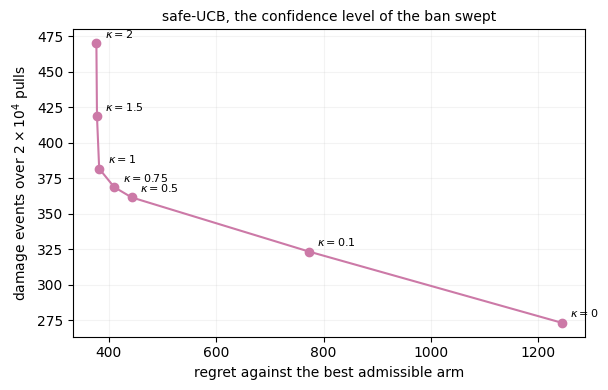

In [ ]:
KAPPAS = np.array([2.0, 1.5, 1.0, 0.75, 0.5, 0.1, 0.0])
RUNS_SW = 200
kappa_rows = np.repeat(KAPPAS, RUNS_SW)[:, None]          # one kappa per row, broadcast over arms
t = time.perf_counter()
res_sw = run_bandit(make_safe_ucb(TAU, SAFE_ARM, kappa=kappa_rows), MU8, T8,
                    len(KAPPAS) * RUNS_SW, seed=40, haz=H8, mu_ref=MU_SAFE, optimal=OPT8)
print(f"sweep, {len(KAPPAS) * RUNS_SW} runs x {T8} pulls: {time.perf_counter() - t:.1f} s\n")

# The runner averages over all rows, so recompute the per-kappa totals from the final counts.
n_fin, D_fin = res_sw["st"]["n"], res_sw["st"]["D"]
banned_fin = res_sw["st"]["banned"]
dmg_k = D_fin.sum(axis=1).reshape(len(KAPPAS), RUNS_SW).mean(axis=1)
reg_k = (n_fin @ (MU_SAFE - MU8)).reshape(len(KAPPAS), RUNS_SW).mean(axis=1)
ban1_k = banned_fin[:, 1].reshape(len(KAPPAS), RUNS_SW).mean(axis=1)
ban0_k = np.nanmean(res_sw["st"]["ban_at"][:, 0].reshape(len(KAPPAS), RUNS_SW), axis=1)
print(f"{'kappa':>6} {'damage':>8} {'regret':>8} {'arm 0 banned at':>16} {'arm 1 banned in':>16}")
for k, d, r, b0, b1 in zip(KAPPAS, dmg_k, reg_k, ban0_k, ban1_k):
    print(f"{k:6.2f} {d:8.1f} {r:8.1f} {b0:16.1f} {100 * b1:15.0f}%")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.plot(reg_k, dmg_k, "o-", color=COLORS["safe"])
for k, r, d in zip(KAPPAS, reg_k, dmg_k):
    ax.annotate(rf"$\kappa={k:g}$", (r, d), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("regret against the best admissible arm")
ax.set_ylabel("damage events over $2\\times10^4$ pulls")
ax.set_title("safe-UCB, the confidence level of the ban swept", fontsize=10)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### Checkpoint 6

Describe the shape of the damage-against-regret curve as $\kappa$ goes from 2 to 0. What happens
at the aggressive end, $\kappa = 0$, and which arm is responsible?

Answer Checkpoint 6)

* **The Pareto Frontier (from $\kappa = 2$ to $\kappa = 0$):**
  * The damage-against-regret curve forms a classic **Pareto frontier** describing the trade-off between policy safety (damage events) and learning speed (regret).
  * **Efficient Region ($\kappa \ge 0.75$):** Moving along the frontier by decreasing $\kappa$ from $2.0$ to $0.75$ yields an excellent trade-off where **cumulative damage decreases** (from $470.1$ to $368.8$) with virtually no regret penalty. This occurs because tighter confidence intervals allow safe-UCB to eliminate the unsafe Arm 0 and Arm 2 much faster.
  * **Inefficient Region ($\kappa < 0.50$):** Below the 'knee' of the Pareto frontier, the trade-off collapses. Decreasing $\kappa$ further causes **regret to skyrocket** exponentially (from $442.5$ to $1243.3$) for negligible reductions in damage.

* **What happens at the aggressive end ($\kappa = 0$):**
  * At $\kappa = 0$, our admissibility test becomes completely non-statistical ($h_i > \tau$). We ban an arm the instant its empirical damage rate exceeds the threshold $0.05$.
  * **Arm 1 (the best admissible arm)** is responsible for this failure. Because its true hazard rate is $h_1 = 0.02$, early random fluctuation or a single unlucky damage event can easily push its empirical damage rate $\hat{h}_1$ above $0.05$ when pull counts are low.
  * Without the statistical safety buffer provided by $\kappa$, **Arm 1 is falsely banned in 41% of the runs**. Once Arm 1 is permanently banned, the algorithm is forced to fall back on the low-reward, known-safe **Arm 7**, causing the massive spike in cumulative regret.

## 8. Analysis

A few sentences each. They are not quizzed, and they come back in later weeks.

1. In section 6 the three optimal designs and the three near-optimal ones differ only through the
   velocity-noise model. If the encoder were replaced by one with ten times the resolution, which
   arms would move, and what would that do to the hours the bandit needs? What does the answer say
   about using a bandit, instead of a model, to choose a gain?

2. Thompson sampling ran on Beta–Bernoulli posteriors in every experiment today, and every reward
   was Bernoulli. The episode outcome in section 6 is genuinely a success or a failure. Name a
   pendulum reward for which the Beta posterior would be misspecified, and say which of the three
   rules you would trust more on it (notes section 3.5, the warning box).

3. In section 7 safe-UCB still caused about twenty damage events before it banned arms 0 and 2.
   Which piece of information, available before the first pull, would remove them? Week 13 returns
   to this question with constrained MDPs and barrier certificates.